# Exploratory Data Analysis (EDA)

## Purpose

The purpose of this notebook is to explore the customer churn dataset through statistical analysis and data visualization.

Exploratory Data Analysis (EDA) helps uncover patterns, relationships, and trends within the data that may influence customer churn behaviour.

The insights generated during this phase will support feature engineering, model development, and business decision-making.

---

## Objectives

The primary objectives of this analysis are to:

- Understand the distribution of the target variable
- Explore feature distributions
- Identify relationships between customer characteristics and churn
- Discover patterns and trends within the data
- Generate business insights
- Support feature engineering decisions
- Inform machine learning model development

---

## Why This Step Matters

Exploratory Data Analysis serves as a bridge between data understanding and model development.

By examining the data in greater detail, we can:

- Identify meaningful patterns
- Detect potential anomalies
- Understand customer behaviour
- Investigate potential churn drivers
- Validate assumptions about the dataset
- Develop hypotheses for model testing

The findings from this phase help ensure that machine learning models are built using relevant and informative features.

---

## Areas of Investigation

This analysis will focus on:

### Target Variable Analysis

- Customer churn distribution
- Class balance assessment

### Customer Characteristics

- Demographic features
- Customer tenure
- Customer account information

### Service Characteristics

- Internet service type
- Subscription services
- Technical support services

### Billing Characteristics

- Monthly charges
- Total charges
- Payment methods
- Contract types

### Feature Relationships

- Churn by customer segment
- Churn by service type
- Churn by billing characteristics
- Churn by tenure and pricing

---

## Expected Outcomes

By the end of this notebook, we expect to:

- Understand the key drivers of customer churn
- Identify important predictive features
- Discover meaningful customer segments
- Generate actionable business insights
- Support future feature engineering activities
- Establish a foundation for machine learning model development

The findings from this analysis will help identify the factors most strongly associated with customer churn and guide subsequent machine learning modelling decisions.

In [9]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

df = pd.read_csv("../data/raw/Telco-Customer-Churn.csv")

print("Dataset Loaded")

Dataset Loaded


# Dataset Overview

## Overview

Before creating visualizations, it is important to confirm the size and structure of the dataset and verify that it has been loaded successfully.

This step provides a high-level understanding of the data that will be used throughout the exploratory analysis process.

---

## Objectives

The dataset overview is used to:

- Verify that the dataset loaded successfully
- Confirm the number of observations and features
- Validate the dataset structure
- Ensure that the expected variables are available
- Establish a foundation for exploratory analysis

---

## Why This Step Matters

Understanding the overall size of the dataset helps determine:

- Whether sufficient data is available for analysis
- The scale of future preprocessing activities
- The feasibility of machine learning model development
- The reliability of statistical findings

It also serves as an initial validation step before investing time in more detailed exploratory analysis.

---

## Expected Outcomes

By reviewing the dataset overview, we expect to:

- Confirm the total number of customer records
- Confirm the number of available features
- Verify that the dataset was loaded correctly
- Ensure that the target variable is present
- Establish confidence in the data before proceeding with visualizations and deeper analysis

The findings from this step will provide context for all subsequent exploratory data analysis activities.

In [10]:
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

Rows: 7043
Columns: 21


# Target Variable Distribution

## Overview

Customer churn is the target variable for this project.

Understanding the distribution of churned and retained customers is a critical step in exploratory data analysis because it provides insight into the composition of the dataset and potential modelling challenges.

---

## Why This Step Matters

Analysing the target variable helps us to:

- Understand class balance
- Assess dataset composition
- Identify potential modelling challenges
- Select appropriate evaluation metrics
- Establish a baseline understanding of customer churn behaviour

---

## Impact on Machine Learning

The distribution of the target variable can have a significant influence on model development and evaluation.

### Balanced Datasets

When classes are relatively balanced:

- Accuracy can provide a useful measure of performance
- Models typically have sufficient examples from each class

### Imbalanced Datasets

When one class substantially outnumbers another:

- Accuracy may become misleading
- Minority class predictions become more difficult
- Additional evaluation metrics become increasingly important

---

## Evaluation Considerations

If class imbalance exists, greater emphasis should be placed on metrics such as:

- Precision
- Recall
- F1 Score
- ROC-AUC

These metrics provide a more detailed assessment of a model's ability to identify customers who are likely to churn.

---

## Objectives

The target variable analysis will be used to:

- Quantify the number of churned and retained customers
- Assess class balance
- Understand customer retention behaviour
- Identify potential modelling considerations
- Support metric selection during model evaluation

---

## Expected Outcomes

By reviewing the target variable distribution, we expect to:

- Understand the proportion of customers who churn
- Determine whether class imbalance exists
- Identify potential modelling challenges
- Establish an evaluation strategy for future machine learning models

The findings from this analysis will guide model development and help ensure that performance is measured using appropriate evaluation metrics.

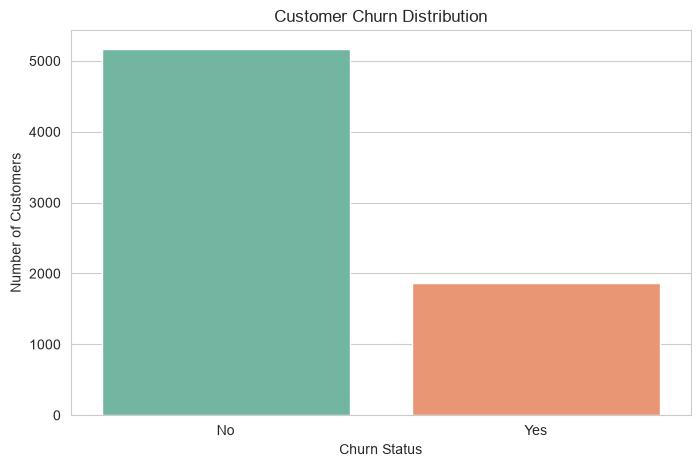

In [11]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

### Findings

#### Churn Distribution

The customer churn distribution confirms that the dataset is **moderately imbalanced**.

##### Class Distribution

The dataset contains:

- **5,174 customers** who remained with the company
- **1,869 customers** who churned

This corresponds to:

- **73.46% retained customers**
- **26.54% churned customers**

---

#### Key Observations

The majority of customers remain with the company, indicating that customer retention is more common than customer churn.

Although the dataset is imbalanced, the imbalance is not severe enough to prevent effective model training. The churn class contains a sufficient number of observations to support classification modelling.

---

#### Business Interpretation

Approximately **one in four customers** leaves the company.

This represents a significant business challenge and highlights the importance of developing an accurate churn prediction model.

Successfully identifying customers who are at risk of churning could help:

- Improve customer retention
- Reduce revenue loss
- Support proactive customer engagement strategies
- Increase customer lifetime value

---

#### Machine Learning Implications

Because retained customers outnumber churned customers, model performance should not be evaluated using Accuracy alone.

A model could achieve relatively high accuracy by predominantly predicting the majority class while failing to identify customers who are likely to churn.

##### Evaluation Metrics

Model evaluation should therefore include:

- Precision
- Recall
- F1 Score
- ROC-AUC

These metrics provide a more reliable assessment of model performance and the model's ability to correctly identify customers who are at risk of leaving the service.

---

#### Overall Assessment

The target variable distribution is suitable for machine learning analysis.

The level of class imbalance is moderate rather than severe, and the dataset contains a sufficient number of churn observations to support the development of robust predictive models.

No immediate class-balancing techniques appear necessary at this stage, although model evaluation should continue to emphasize metrics designed for imbalanced classification problems.

# Churn by Gender

## Overview

This analysis investigates whether customer churn differs between gender groups.

Understanding whether churn rates vary across demographic groups may provide valuable insight into customer retention patterns and potential customer segmentation opportunities.

---

## Why This Step Matters

Demographic variables are often examined during exploratory data analysis to determine whether certain customer groups exhibit different behaviours or outcomes.

Analysing churn by gender helps us to:

- Identify potential demographic trends
- Assess differences in customer retention behaviour
- Explore customer segmentation opportunities
- Determine whether gender may contribute predictive value during model development

---

## Business Context

If meaningful differences exist between gender groups, targeted retention strategies could potentially be developed for specific customer segments.

Conversely, if churn behaviour is similar across groups, other factors may be more important drivers of customer retention and attrition.

---

## Objectives

This analysis will be used to:

- Compare churn levels across gender groups
- Assess whether gender appears related to customer attrition
- Identify potential demographic patterns
- Evaluate the usefulness of gender as a predictive feature

---

## Expected Outcomes

By reviewing churn behaviour across gender groups, we expect to:

- Understand whether customer churn differs by gender
- Identify potential demographic patterns
- Determine whether gender may contribute predictive value within future machine learning models
- Generate business insights that can inform customer retention strategies

The findings from this analysis will help determine whether demographic characteristics influence customer churn behaviour and whether gender should be considered an important feature during model development.

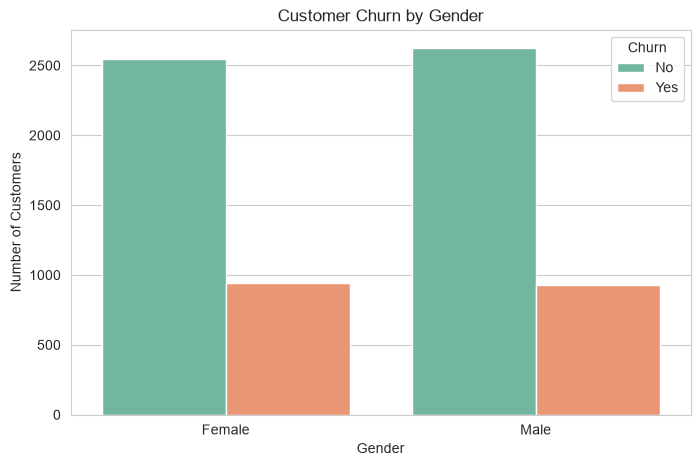

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="gender",
    hue="Churn",
    palette="Set2"
)

plt.title("Customer Churn by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.show()


### Findings

#### Gender Distribution and Churn

The gender analysis suggests that customer churn is relatively similar across both gender groups.

---

#### Key Observations

- Male and female customers are represented in similar numbers within the dataset.
- Both groups exhibit comparable levels of customer retention and churn.
- No substantial difference in churn behaviour is immediately apparent based on gender alone.

These observations suggest that gender has a limited influence on customer churn when considered independently.

---

#### Business Interpretation

Gender does not appear to be a strong individual predictor of customer churn.

This finding suggests that customer attrition is more likely driven by service-related, contractual, and behavioural factors than by demographic characteristics alone.

Potential drivers of churn may include:

- Contract type
- Service subscriptions
- Internet service type
- Billing characteristics
- Customer tenure

These variables will be investigated in greater detail throughout the exploratory analysis process.

---

#### Machine Learning Implications

Based on the observed distribution, gender is unlikely to be one of the most influential predictors within the final machine learning model.

However, the feature may still contribute predictive value when combined with other customer characteristics and service-related variables.

As a result:

- Gender will be retained for modelling purposes.
- Its importance will be evaluated during feature engineering and model development.
- More emphasis should be placed on variables that exhibit stronger relationships with customer churn.

---

#### Overall Assessment

The analysis indicates that gender alone has limited explanatory power with respect to customer churn.

This suggests that retention strategies are likely to be more effective when focused on customer behaviour, service usage patterns, billing characteristics, and contractual relationships rather than demographic segmentation alone.

---

#### Next Steps

The next stage of analysis will investigate additional customer and service-related features that may have a stronger relationship with churn, including:

- Contract type
- Internet service type
- Customer tenure
- Monthly charges
- Payment methods

These variables are expected to provide deeper insight into the factors driving customer attrition.

# Churn by Contract Type

## Overview

Customer contracts may influence customer retention because they affect customer commitment, switching behaviour, and the likelihood of remaining with a service provider over time.

This analysis investigates whether customers on different contract types exhibit different churn rates.

---

## Contract Types

The dataset contains three contract categories:

- Month-to-month
- One year
- Two year

Each contract type represents a different level of customer commitment and may influence the probability of customer churn.

---

## Why This Step Matters

Contract type is often one of the strongest predictors of customer retention.

Customers with longer contractual commitments may be:

- Less likely to switch providers
- More invested in the service
- More resistant to short-term dissatisfaction

Conversely, customers with shorter-term contracts may have greater flexibility to leave the service.

---

## Business Significance

Understanding the relationship between contract type and churn can help organizations:

- Identify high-risk customer segments
- Improve customer retention strategies
- Design more effective contract offerings
- Develop targeted retention campaigns
- Reduce customer attrition

These insights can directly support customer retention initiatives and long-term revenue growth.

---

## Objectives

This analysis will be used to:

- Compare churn rates across contract types
- Identify which contract groups are most likely to churn
- Assess the relationship between customer commitment and retention
- Determine whether contract type may be an important predictive feature

---

## Expected Outcomes

By reviewing churn behaviour across contract categories, we expect to:

- Understand how customer commitment influences retention
- Identify customer groups with elevated churn risk
- Generate actionable business insights
- Determine the predictive value of contract type for machine learning models

The findings from this analysis may reveal one of the strongest drivers of customer churn and help guide both business strategy and model development.

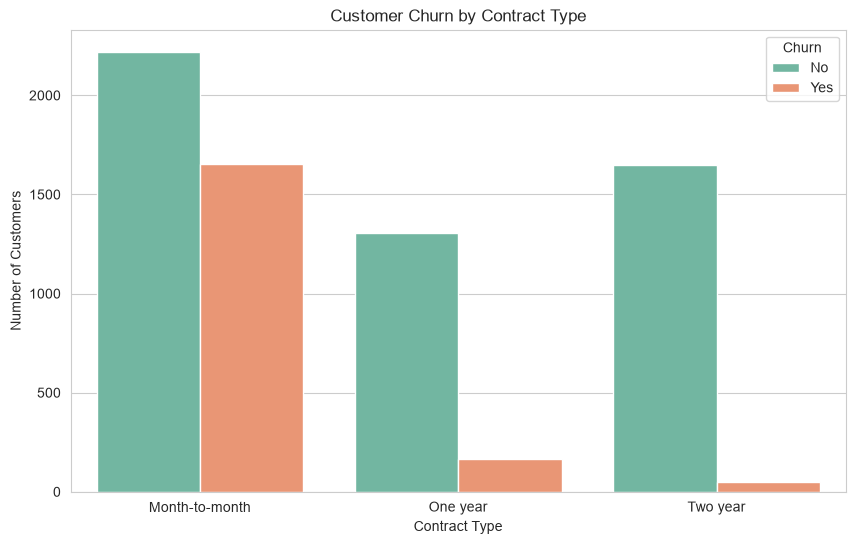

In [13]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn",
    palette="Set2"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

### Findings

#### Contract Type and Customer Churn

The contract type analysis reveals a strong relationship between contract duration and customer churn.

---

#### Key Observations

##### Month-to-Month Contracts

Customers on **month-to-month contracts** exhibit the highest churn rates within the dataset.

The flexibility of these contracts allows customers to leave the service with minimal commitment, increasing the likelihood of customer attrition.

##### One-Year Contracts

Customers on **one-year contracts** demonstrate substantially lower churn rates than month-to-month customers.

This suggests that increased contractual commitment is associated with improved customer retention.

##### Two-Year Contracts

Customers on **two-year contracts** exhibit the lowest churn rates and the highest levels of customer retention.

These customers appear significantly less likely to leave the company than customers on shorter-term agreements.

---

#### Business Interpretation

Contract commitment appears to be one of the strongest factors influencing customer retention.

Customers who are not locked into long-term agreements can leave the service more easily, making month-to-month subscribers significantly more likely to churn.

Conversely, customers with one-year and two-year contracts are considerably more likely to remain with the company.

This pattern suggests that contract length plays an important role in customer loyalty and long-term retention.

---

#### Potential Business Actions

The organisation could consider several retention-focused strategies, including:

- Encouraging customers to migrate from month-to-month plans to longer-term contracts
- Offering incentives for annual or multi-year contracts
- Providing targeted retention campaigns for month-to-month customers
- Developing loyalty programs for customers nearing contract renewal
- Identifying high-risk month-to-month customers for proactive engagement

These initiatives could help reduce churn and improve customer lifetime value.

---

#### Machine Learning Implications

Contract type is likely to be one of the most important predictive features in the final machine learning model.

The clear differences in churn behaviour across contract categories suggest that this variable contains strong predictive information.

As a result:

- Contract type should be retained during feature engineering
- Appropriate categorical encoding should be applied during preprocessing
- Feature importance analysis should closely monitor this variable during model development

---

#### Overall Assessment

The analysis indicates that contract type is a strong indicator of customer retention behaviour.

Among all variables examined so far, contract type appears to be one of the strongest candidates for predicting customer churn and is likely to contribute significantly to model performance.

# Churn by Internet Service Type

## Overview

Internet service offerings may influence customer satisfaction, perceived value, pricing, service quality, and ultimately customer retention.

This analysis examines whether customer churn behaviour differs across internet service categories.

---

## Internet Service Categories

The dataset includes three internet service types:

- DSL
- Fiber optic
- No internet service

Each service category may offer different customer experiences, pricing structures, and performance characteristics that could influence churn behaviour.

---

## Why This Step Matters

Internet service is one of the primary products offered by the company and may have a significant impact on customer satisfaction and loyalty.

Understanding how churn varies across service types can help identify:

- High-risk customer segments
- Potential service-related retention challenges
- Opportunities for targeted retention strategies
- Features that may contribute strongly to predictive modelling

---

## Business Significance

Differences in churn behaviour between service types may indicate underlying factors such as:

- Service quality perceptions
- Pricing sensitivity
- Customer expectations
- Competitive alternatives
- Product satisfaction

Understanding these relationships can help guide both operational improvements and customer retention initiatives.

---

## Objectives

This analysis will be used to:

- Compare churn rates across internet service categories
- Identify customer groups with elevated churn risk
- Assess the relationship between service type and retention
- Generate business insights regarding customer behaviour
- Evaluate the predictive value of internet service type

---

## Expected Outcomes

By examining churn behaviour across internet service categories, we expect to:

- Understand whether certain service types experience higher churn rates
- Identify internet service groups that may require targeted retention efforts
- Generate actionable business insights
- Determine whether internet service type is an important feature for machine learning modelling

The findings from this analysis may reveal important service-related drivers of customer churn and support both business decision-making and model development.

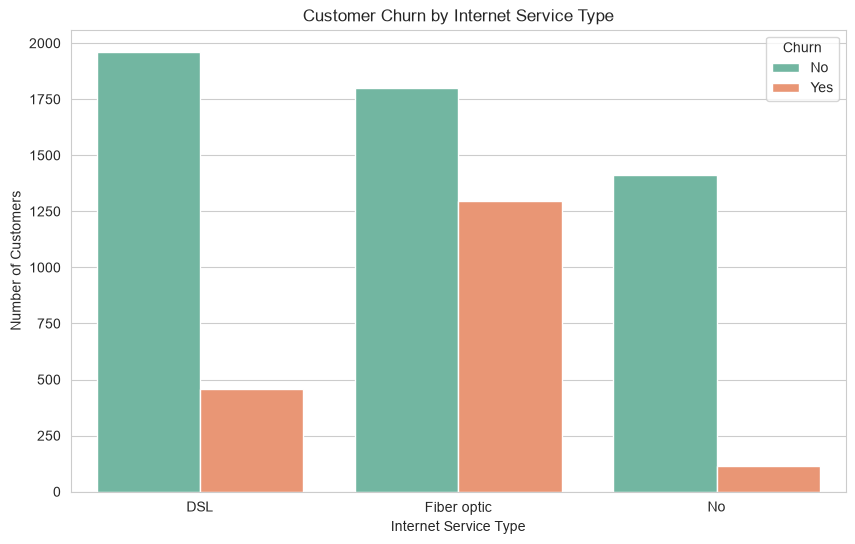

In [14]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn",
    palette="Set2")

plt.title("Customer Churn by Internet Service Type")
plt.xlabel("Internet Service Type")
plt.ylabel("Number of Customers")

plt.show()

### Findings

#### Internet Service Type and Customer Churn

The internet service analysis reveals a strong relationship between internet service type and customer churn.

---

#### Key Observations

##### Fiber Optic Customers

Customers using **Fiber Optic** internet services exhibit the highest levels of churn within the dataset.

This customer segment appears considerably more likely to leave the company than customers using other internet service options.

##### DSL Customers

Customers using **DSL** services demonstrate substantially lower churn rates than Fiber Optic customers.

This suggests stronger customer retention and greater service stability within this group.

##### Customers Without Internet Service

Customers with **No Internet Service** appear to have the lowest churn rates overall and represent the most stable customer segment observed in this analysis.

---

#### Business Interpretation

Fiber Optic customers appear significantly more likely to leave the company than other customer groups.

Several factors may contribute to this behaviour, including:

- Higher monthly service costs
- Increased customer expectations
- Service quality concerns
- Greater market competition within high-speed internet services

Although Fiber Optic services attract a substantial number of customers, they may also represent a higher-risk customer segment from a retention perspective.

---

#### Comparison Across Service Types

The differences in retention behaviour across internet service categories are substantial.

##### DSL vs Fiber Optic

DSL customers display considerably stronger retention rates than Fiber Optic customers.

This indicates that internet service type may influence customer satisfaction, loyalty, or perceived value.

##### No Internet Service Customers

Customers without internet services appear highly stable and demonstrate the lowest levels of churn observed in the analysis.

This group may represent customers who rely on a narrower set of services and therefore exhibit stronger long-term retention behaviour.

---

#### Machine Learning Implications

Internet service type is likely to be an important predictive feature in the final machine learning model.

The clear differences in churn behaviour across service categories suggest that this feature contains strong predictive information.

As a result:

- Internet service type should be retained during feature engineering.
- Appropriate categorical encoding should be applied during preprocessing.
- Feature importance analysis should closely evaluate this variable during model development.

---

#### Relationship to Previous Findings

This finding complements the earlier contract type analysis.

So far, the strongest churn indicators identified through exploratory analysis appear to be:

1. Contract type
2. Internet service type

Both variables show substantial differences in customer retention behaviour and are likely to play an important role in predictive modelling.

---

#### Overall Assessment

The analysis suggests that internet service type is one of the strongest predictors of customer churn identified so far.

Customers using Fiber Optic services appear particularly susceptible to churn and may warrant targeted retention initiatives, service quality reviews, or specialised customer engagement strategies.

This feature should be considered a high-priority variable during feature engineering and machine learning model development.

# Monthly Charges Distribution

## Overview

Monthly charges represent the amount billed to a customer each month for the services they subscribe to.

Analysing the distribution of monthly charges helps us understand customer spending patterns and assess whether pricing may influence customer retention and churn behaviour.

---

## Why This Step Matters

Billing-related features often play an important role in customer satisfaction and retention.

Understanding how monthly charges are distributed across the customer base can help identify:

- Pricing patterns
- Customer spending segments
- Potential outliers
- Differences between low-cost and high-cost customers
- Relationships between pricing and churn

---

## Business Significance

Monthly charges directly affect the cost of service experienced by customers.

Higher monthly fees may lead to:

- Increased price sensitivity
- Greater expectations regarding service quality
- Increased likelihood of comparing competitors
- Higher customer churn risk

Conversely, lower-cost customers may exhibit different retention behaviours.

Understanding these patterns can support pricing, retention, and customer experience strategies.

---

## Objectives

This analysis will be used to:

- Examine the distribution of monthly charges
- Identify customer spending patterns
- Detect unusual values or potential outliers
- Assess the range of customer pricing plans
- Investigate whether pricing may influence customer churn

---

## Areas of Investigation

The analysis will focus on:

### Distribution Characteristics

- Minimum monthly charges
- Maximum monthly charges
- Central tendencies
- Distribution shape

### Customer Segmentation

- Low-cost customer segments
- Medium-cost customer segments
- High-cost customer segments

### Potential Churn Relationships

- Whether customers with higher monthly charges appear more likely to churn
- Whether pricing influences customer retention behaviour

---

## Expected Outcomes

By reviewing the distribution of monthly charges, we expect to:

- Gain a better understanding of customer billing patterns
- Identify potential outliers or unusual observations
- Understand how pricing varies across the customer base
- Generate insights that may explain customer churn behaviour
- Identify whether monthly charges should be considered an important predictive feature

The findings from this analysis will support both business insight generation and future machine learning model development.

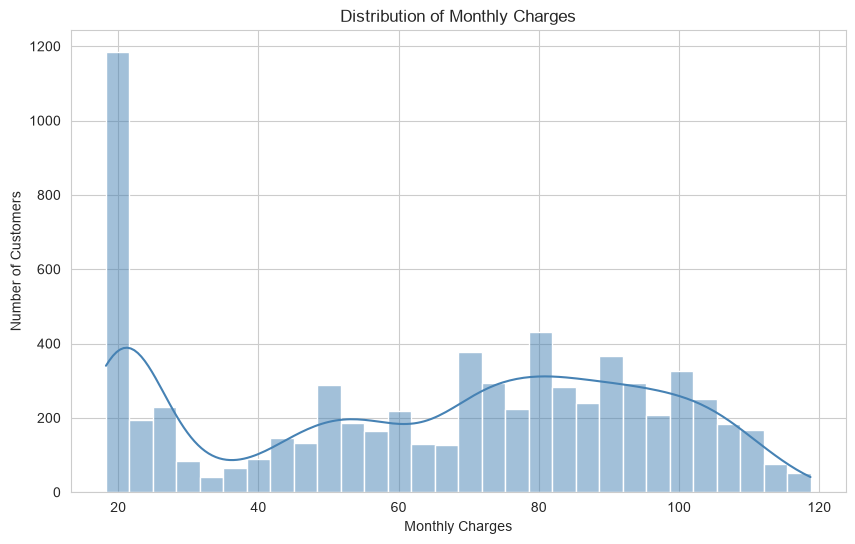

In [15]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["MonthlyCharges"],
    bins=30,
    kde=True,
    color="steelblue")

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.show()

### Findings

#### Distribution of Monthly Charges

The distribution of monthly charges reveals several interesting characteristics of the customer base and suggests the presence of distinct customer segments.

---

#### Key Observations

##### Price Range

Monthly charges range from approximately **$18** to **$119** per month.

This wide range reflects the diversity of services, subscription packages, and billing plans available to customers.

##### Distribution Shape

The distribution is **not normally distributed**.

Several noticeable clusters of customers are present across different pricing levels.

##### Customer Segments

A large concentration of customers is clustered around lower monthly charges.

A second concentration appears within the **$70 to $110** range.

This pattern suggests the existence of multiple customer segments with varying service packages and pricing structures.

---

#### Business Interpretation

The presence of multiple peaks within the distribution suggests that customers subscribe to different combinations of services and pricing tiers.

Higher monthly charges may be associated with customers who:

- Subscribe to additional services
- Use premium service packages
- Have Fiber Optic internet services
- Purchase bundled telecommunications products

These customer segments may have different retention behaviours and levels of churn risk.

---

#### Customer Retention Considerations

Monthly pricing can have a direct impact on customer satisfaction and retention.

Customers with higher monthly charges may:

- Have greater service expectations
- Be more sensitive to perceived value
- Be more likely to compare competing service providers
- Require stronger retention efforts

Further analysis will investigate whether higher monthly charges are associated with increased churn rates.

---

#### Data Quality Assessment

No obvious outliers or unrealistic values are visible within the distribution.

The observed range of monthly charges appears consistent with expectations for a telecommunications services provider.

The feature appears:

- Complete
- Realistic
- Well-distributed
- Suitable for machine learning analysis

No immediate data quality concerns were identified.

---

#### Machine Learning Implications

The **MonthlyCharges** feature is likely to be an important predictor of customer churn because billing costs often influence customer retention behaviour.

The observed variation in pricing suggests that this feature contains meaningful information that may help distinguish between customers who remain with the company and those who leave.

As a result:

- MonthlyCharges should be retained during feature engineering.
- Scaling will likely be required during preprocessing.
- Its predictive importance should be evaluated during model development.

---

#### Overall Assessment

Monthly charges appear to capture meaningful differences between customer segments and service plans.

Based on the distribution and business context, **MonthlyCharges** is expected to be one of the more influential numerical variables within the final machine learning model.

The next stage of analysis will investigate the direct relationship between monthly charges and customer churn to determine whether higher-paying customers exhibit different retention behaviours.

# Customer Tenure Distribution

## Overview

Customer tenure measures the length of time a customer has remained with the company.

Tenure is often one of the most important indicators of customer loyalty, engagement, and long-term retention.

Understanding the distribution of customer tenure provides insight into the composition of the customer base and helps identify different stages of the customer lifecycle.

---

## Why This Step Matters

Customer tenure can influence many aspects of customer behaviour, including:

- Service adoption
- Customer satisfaction
- Purchase patterns
- Customer loyalty
- Churn risk

Customers at different stages of their relationship with the company may exhibit substantially different retention behaviours.

---

## Business Significance

Understanding customer tenure can help the organization:

- Identify newly acquired customers
- Recognize long-term loyal customers
- Understand retention patterns
- Develop targeted retention strategies
- Improve customer lifecycle management

Customer loyalty often develops over time, making tenure a potentially important factor in customer churn prediction.

---

## Objectives

This analysis will be used to:

- Examine the distribution of customer tenure
- Understand the mix of new and long-term customers
- Identify customer lifecycle patterns
- Assess potential relationships between tenure and churn
- Evaluate tenure as a predictive feature

---

## Areas of Investigation

### Customer Lifecycle Distribution

The analysis will examine:

- New customers
- Mid-tenure customers
- Long-term customers

### Retention Implications

The analysis will explore whether:

- New customers are more likely to leave
- Customer loyalty strengthens over time
- Long-term customers exhibit lower churn rates

### Predictive Value

The findings will help determine whether tenure may serve as an important feature for machine learning modelling.

---

## Expected Outcomes

By reviewing the customer tenure distribution, we expect to:

- Understand the composition of the customer base
- Identify customer lifecycle patterns
- Evaluate the relationship between tenure and customer retention
- Generate business insights regarding customer loyalty
- Determine the predictive importance of tenure

The findings from this analysis may reveal whether long-term customer relationships contribute to retention and whether tenure is a key driver of customer churn.

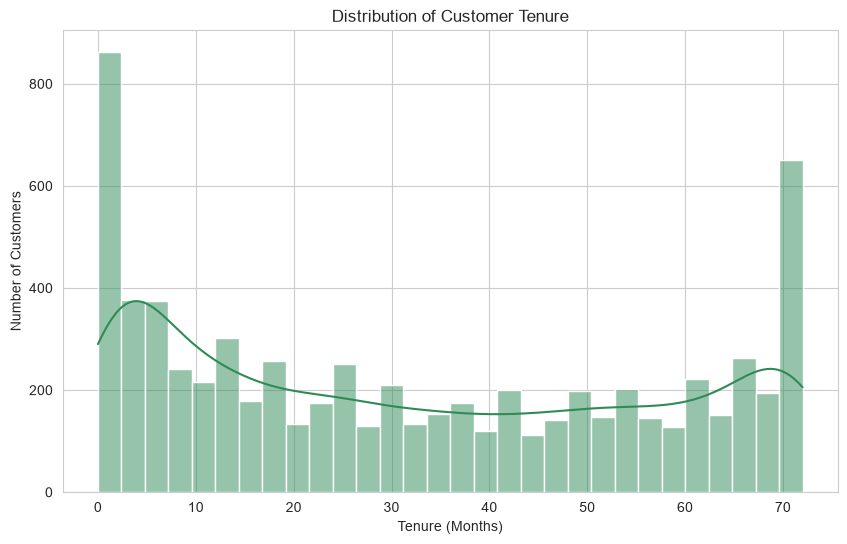

In [16]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["tenure"],
    bins=30,
    kde=True,
    color="seagreen")

plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

### Findings

#### Customer Tenure Distribution

The tenure distribution reveals two prominent customer groups within the dataset.

---

#### Key Observations

##### New Customers

A large concentration of customers have very short tenure periods.

This indicates that a significant portion of the customer base is relatively new to the company's services.

##### Long-Term Customers

Another substantial group has remained with the company for the maximum observed tenure of approximately **72 months**.

These customers represent highly established relationships and demonstrate long-term engagement with the company.

##### Mid-Tenure Customers

Relatively fewer customers fall within the mid-range tenure periods.

This creates a distribution with noticeable concentrations at both the lower and upper ends of the tenure spectrum.

---

#### Business Interpretation

The distribution suggests a customer base composed of two distinct groups:

- New customers who have recently joined the service
- Long-term customers who have maintained established relationships with the company

This pattern may indicate strong customer loyalty among long-term customers while simultaneously highlighting the importance of retaining customers during the early stages of their relationship with the company.

---

#### Customer Lifecycle Insights

The large number of customers with short tenure suggests that churn may be most likely to occur early in the customer lifecycle.

Customers who are still evaluating the service or adjusting to their subscriptions may be more susceptible to leaving.

Conversely, customers who remain with the company for several years may become increasingly loyal and less likely to churn.

This pattern aligns with common customer retention behaviour, where loyalty tends to strengthen over time.

---

#### Business Implications

The findings suggest several potential retention opportunities:

- Focus retention efforts on newly acquired customers
- Improve onboarding and early customer experiences
- Identify factors that encourage long-term loyalty
- Develop targeted interventions for customers during their first months of service

Strengthening retention during the early stages of the customer journey could have a meaningful impact on reducing overall churn.

---

#### Machine Learning Implications

Customer tenure is likely to be one of the most important predictive variables within the final machine learning model.

The observed distribution suggests that tenure captures meaningful information about customer loyalty, retention risk, and lifecycle stage.

As a result:

- Tenure should be retained during feature engineering.
- Appropriate scaling should be applied during preprocessing.
- Feature importance analysis should closely evaluate this variable during model development.

---

#### Overall Assessment

Customer tenure appears to be a strong indicator of customer retention behaviour.

Among the variables analysed so far, tenure is emerging as one of the most promising predictors of churn, alongside:

- Contract type
- Internet service type

These features are likely to play a significant role in explaining customer attrition and improving predictive model performance.

---

#### Next Steps

The next stage of analysis will investigate the direct relationship between customer tenure and churn behaviour.

This will help determine whether customers with shorter tenures are significantly more likely to leave the company and quantify the impact of tenure on customer retention.

# Tenure vs Churn

## Overview

Customer tenure is expected to have a significant influence on churn behaviour.

Customers who have maintained longer relationships with the company may exhibit stronger loyalty, while newer customers may be more likely to leave before establishing long-term commitment.

This analysis compares the tenure distributions of customers who remained with the company and those who churned.

---

## Why This Step Matters

Tenure is one of the most important indicators of customer loyalty and retention.

Examining tenure alongside churn can help determine whether:

- Churn occurs more frequently among newer customers
- Long-term customers demonstrate stronger retention
- Customer loyalty increases over time
- Retention strategies should focus on specific stages of the customer lifecycle

---

## Business Significance

Understanding the relationship between tenure and churn can help the organisation:

- Identify high-risk customer groups
- Improve onboarding experiences
- Develop early-stage retention initiatives
- Strengthen long-term customer relationships
- Reduce customer attrition

Insights from this analysis may reveal critical periods during which customers are most vulnerable to leaving the service.

---

## Objectives

This analysis will be used to:

- Compare tenure distributions between churned and retained customers
- Identify differences in customer lifecycle behaviour
- Assess the relationship between loyalty and churn risk
- Determine whether tenure is a strong predictor of customer retention

---

## Areas of Investigation

### Retained Customers

The analysis will examine whether retained customers tend to have longer tenures and stronger relationships with the company.

### Churned Customers

The analysis will investigate whether customers who churn tend to leave earlier in their customer journey.

### Customer Loyalty

The results will help determine whether customer loyalty appears to strengthen as tenure increases.

---

## Expected Outcomes

By comparing tenure distributions across churn outcomes, we expect to:

- Understand how customer tenure influences retention
- Identify high-risk stages within the customer lifecycle
- Generate actionable retention insights
- Confirm whether tenure is an important predictive feature

The findings from this analysis will help determine whether customer loyalty increases with longer tenure periods and whether tenure should be considered a key driver of customer churn.

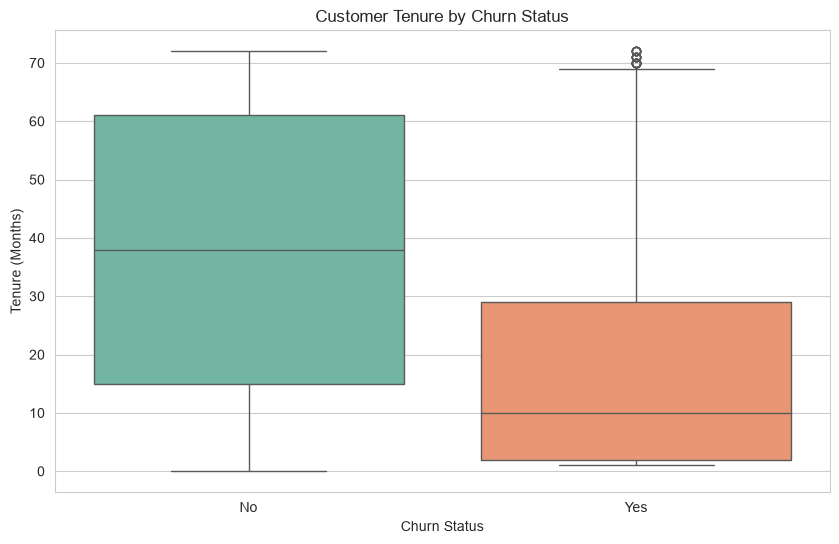

In [17]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    hue="Churn",
    palette="Set2",
    legend=False)

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")

plt.show()

# Tenure vs Churn

## Overview

Customer tenure is expected to have a significant influence on churn behaviour.

Customers who have maintained longer relationships with the company may exhibit stronger loyalty, while newer customers may be more likely to leave before establishing long-term commitment.

This analysis compares the tenure distributions of customers who remained with the company and those who churned.

---

## Why This Step Matters

Tenure is one of the most important indicators of customer loyalty and retention.

Examining tenure alongside churn can help determine whether:

- Churn occurs more frequently among newer customers
- Long-term customers demonstrate stronger retention
- Customer loyalty increases over time
- Retention strategies should focus on specific stages of the customer lifecycle

---

## Business Significance

Understanding the relationship between tenure and churn can help the organisation:

- Identify high-risk customer groups
- Improve onboarding experiences
- Develop early-stage retention initiatives
- Strengthen long-term customer relationships
- Reduce customer attrition

Insights from this analysis may reveal critical periods during which customers are most vulnerable to leaving the service.

---

## Objectives

This analysis will be used to:

- Compare tenure distributions between churned and retained customers
- Identify differences in customer lifecycle behaviour
- Assess the relationship between loyalty and churn risk
- Determine whether tenure is a strong predictor of customer retention

---

## Areas of Investigation

### Retained Customers

The analysis will examine whether retained customers tend to have longer tenures and stronger relationships with the company.

### Churned Customers

The analysis will investigate whether customers who churn tend to leave earlier in their customer journey.

### Customer Loyalty

The results will help determine whether customer loyalty appears to strengthen as tenure increases.

---

## Expected Outcomes

By comparing tenure distributions across churn outcomes, we expect to:

- Understand how customer tenure influences retention
- Identify high-risk stages within the customer lifecycle
- Generate actionable retention insights
- Confirm whether tenure is an important predictive feature

The findings from this analysis will help determine whether customer loyalty increases with longer tenure periods and whether tenure should be considered a key driver of customer churn.

# Monthly Charges vs Churn

## Overview

Monthly charges may influence customer retention because customers paying higher fees often have different expectations regarding service quality, perceived value, customer support, and overall service experience.

This analysis compares monthly charges across customers who remained with the company and those who churned.

---

## Why This Step Matters

Pricing is frequently an important factor in customer decision-making and retention behaviour.

Understanding the relationship between monthly charges and churn can help determine whether:

- Higher-paying customers are more likely to leave
- Price sensitivity contributes to customer attrition
- Customer value perceptions influence retention
- Billing-related features provide strong predictive value

---

## Business Significance

Monthly charges directly affect how customers perceive the value they receive from their services.

Customers paying higher monthly fees may:

- Expect higher service quality
- Be more sensitive to service issues
- Compare competitor offerings more frequently
- Have greater expectations regarding customer support

Understanding these relationships can help the organization improve pricing strategies and customer retention efforts.

---

## Objectives

This analysis will be used to:

- Compare monthly charges between churned and retained customers
- Assess whether pricing influences customer retention
- Identify potential pricing-related churn patterns
- Generate business insights regarding customer value perception
- Evaluate monthly charges as a predictive feature

---

## Areas of Investigation

### Retained Customers

The analysis will examine whether retained customers tend to have higher or lower monthly charges.

### Churned Customers

The analysis will investigate whether customers who leave the company are concentrated within specific pricing ranges.

### Pricing and Retention

The results will help determine whether monthly billing costs appear to influence customer loyalty and churn risk.

---

## Expected Outcomes

By comparing monthly charges across churn outcomes, we expect to:

- Understand the relationship between pricing and customer churn
- Identify potential high-risk pricing segments
- Generate business insights related to customer value perception
- Evaluate the predictive importance of monthly charges

The findings from this analysis will help determine whether pricing differences are associated with customer attrition and whether monthly charges should be considered a key feature in churn prediction models.

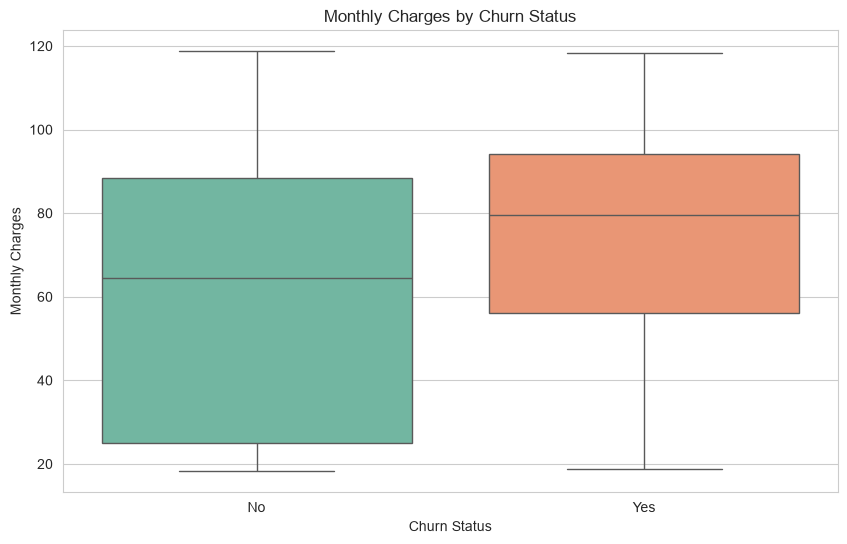

In [18]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette="Set2",
    legend=False)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")

plt.show()

### Findings

#### Monthly Charges and Customer Churn

The analysis suggests a meaningful relationship between monthly charges and customer churn behaviour.

---

#### Key Observations

##### Churned Customers

Customers who churned generally have higher monthly charges than customers who remained with the company.

The distribution indicates that customers leaving the service tend to be concentrated within higher pricing ranges.

##### Retained Customers

Customers who remained with the company generally exhibit lower monthly charges than churned customers.

##### Median Monthly Charges

The median monthly charge for churned customers is noticeably higher than the median monthly charge for retained customers.

This pattern suggests that customers paying higher monthly fees may face an increased risk of churn.

---

#### Business Interpretation

Price appears to be an important factor influencing customer retention.

Customers with higher monthly bills may be:

- More sensitive to perceived value
- More likely to compare alternative providers
- More likely to switch if they experience service issues
- Less tolerant of service disruptions or support concerns

These findings suggest that higher-paying customers may require additional attention from customer success and retention teams.

---

#### Relationship to Previous Findings

This finding complements several patterns identified earlier in the exploratory analysis.

Previous analyses showed that:

- Fiber Optic customers experience higher churn rates
- Month-to-month customers experience higher churn rates
- Customers with shorter tenure are more likely to churn

Because Fiber Optic services often carry higher monthly charges, these variables may be interconnected and should be examined further during feature engineering and model development.

This highlights the possibility that pricing, service type, and contractual commitment collectively influence churn behaviour.

---

#### Machine Learning Implications

The **MonthlyCharges** feature is likely to be an important predictor of customer churn.

Together with:

- Contract Type
- Internet Service Type
- Customer Tenure

MonthlyCharges appears to be one of the strongest candidate predictors identified during exploratory analysis.

As a result:

- MonthlyCharges should be retained during feature engineering.
- Appropriate feature scaling should be applied during preprocessing.
- Feature importance analysis should closely evaluate this variable during model development.

---

#### Emerging Churn Drivers

The exploratory analysis conducted so far suggests that customer churn is primarily associated with service-related and behavioural factors rather than demographic characteristics.

The strongest predictors identified to date include:

- Short customer tenure
- Month-to-month contracts
- Fiber Optic internet service
- Higher monthly charges

These variables consistently demonstrate clear relationships with customer attrition and are expected to contribute significantly to predictive model performance.

---

#### Overall Assessment

Monthly charges appear to play an important role in customer retention behaviour.

Customers paying higher monthly fees seem more likely to leave the service, suggesting that pricing, perceived value, and service expectations may influence churn decisions.

The findings reinforce the importance of combining billing, service, and customer lifecycle variables when building machine learning models for churn prediction.

# EDA Summary and Key Insights

## Overview

The Exploratory Data Analysis (EDA) phase identified several important factors associated with customer churn and provided valuable insight into customer behaviour, retention patterns, and potential drivers of attrition.

The findings from this analysis will guide feature engineering decisions and support the development of effective machine learning models.

---

## Key Findings

### Demographic Factors

#### Gender

Gender does not appear to have a substantial influence on customer churn.

##### Key Observations

- Churn behaviour is relatively similar for male and female customers.
- No meaningful differences in retention patterns were identified based on gender alone.
- Gender is unlikely to be a primary driver of customer churn.

##### Business Implication

Customer retention strategies are likely to be more effective when focused on behavioural and service-related factors rather than demographic characteristics.

---

### Contract Type

Contract type emerged as one of the strongest predictors of customer churn.

##### Key Observations

- Month-to-month customers exhibit the highest churn rates.
- Customers on one-year contracts demonstrate substantially stronger retention.
- Customers on two-year contracts exhibit the lowest churn rates.

##### Business Implication

Longer-term contracts appear to encourage customer loyalty and reduce customer attrition.

---

### Internet Service Type

Internet service type shows a strong relationship with customer retention behaviour.

##### Key Observations

- Fiber Optic customers experience considerably higher churn rates than DSL customers.
- DSL customers demonstrate stronger retention rates.
- Customers without internet service display the lowest churn levels.

##### Business Implication

Fiber Optic customers may represent a high-risk customer segment that requires targeted retention initiatives.

---

### Customer Tenure

Customer tenure appears to be one of the most important factors influencing churn.

##### Key Observations

- Churn is strongly associated with shorter tenure periods.
- Customers with longer tenures are significantly more likely to remain with the company.
- Many churned customers leave during the early stages of the customer lifecycle.

##### Business Implication

Customer retention efforts should focus heavily on newly acquired customers and early-stage customer engagement.

---

### Monthly Charges

Monthly billing amounts appear closely related to customer churn behaviour.

##### Key Observations

- Customers with higher monthly charges are more likely to churn.
- Churned customers generally have higher monthly fees than retained customers.
- Pricing appears to influence perceived value and customer retention decisions.

##### Business Implication

Higher-paying customers may require additional customer success and retention support to reduce churn risk.

---

## Most Important Candidate Features

Based on the exploratory analysis, the strongest predictors of churn are likely to be:

1. Contract Type
2. Customer Tenure
3. Internet Service Type
4. Monthly Charges

These features consistently demonstrated meaningful relationships with customer churn and should receive particular attention during feature engineering and model development.

---

## Emerging Churn Drivers

The analysis suggests that customer churn is driven primarily by service-related and behavioural factors rather than demographic characteristics.

Key churn drivers identified include:

- Contract commitment
- Internet service type
- Monthly billing characteristics
- Length of customer relationship

Together, these variables provide valuable insight into customer retention behaviour and are expected to contribute significantly to machine learning model performance.

---

## Data Quality Assessment

The exploratory analysis also confirmed that the dataset is:

- Well-structured
- Largely complete
- Suitable for machine learning analysis
- Rich in both numerical and categorical features

The primary data quality issue identified remains the **TotalCharges** feature, which requires conversion from a string to a numerical variable during preprocessing.

---

## Next Steps

The next notebook will focus on **Feature Engineering and Data Preparation**.

### Planned Activities

The feature engineering phase will include:

- Cleaning the **TotalCharges** feature
- Handling invalid or missing values
- Encoding categorical variables
- Scaling numerical features
- Creating reusable preprocessing pipelines
- Preparing the data for machine learning models
- Creating the final feature matrix and target variable

---

## Expected Outcome

The feature engineering phase will transform the raw dataset into a clean, machine-learning-ready format suitable for:

- Model development
- Model comparison
- Hyperparameter tuning
- Final pipeline construction

These activities will provide the foundation for building accurate and reliable customer churn prediction models.